Task 1: Temperature

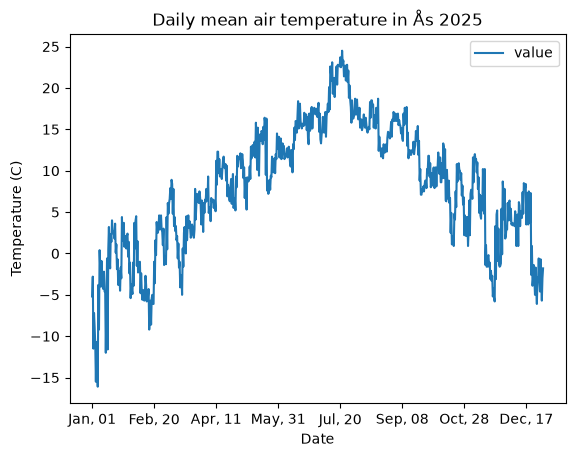

In [26]:
import datetime as dt
import matplotlib.pyplot as plt
import pandas as pd
import requests


endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {'sources': 'SN17850',
              'elements': 'mean(air_temperature P1D)',
              'referencetime': '2025-01-01/2025-12-31',
             }

client_id = open('/Users/norahattrem/Desktop/Programmering/Visual Studio Code/INF201/frost_credentials.txt').read().strip()

frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert frost_response.status_code == 200

frost_json = frost_response.json()

data = frost_json['data']

# This will return a Dataframe with all of the observations in a table format
list = []
df = pd.DataFrame()
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = dt.datetime.strftime(dt.datetime.fromisoformat(data[i]['referenceTime']),'%b, %d')
    row['sourceId'] = data[i]['sourceId']
    list.append(row)

df = pd.concat(list)

df = df.reset_index()

df.plot(x='referenceTime', y='value')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.title('Daily mean air temperature in Ås 2025')
plt.show()


# Need to add summary table

Resource: https://frost.met.no/python_example.html

Task 2: Precipitation

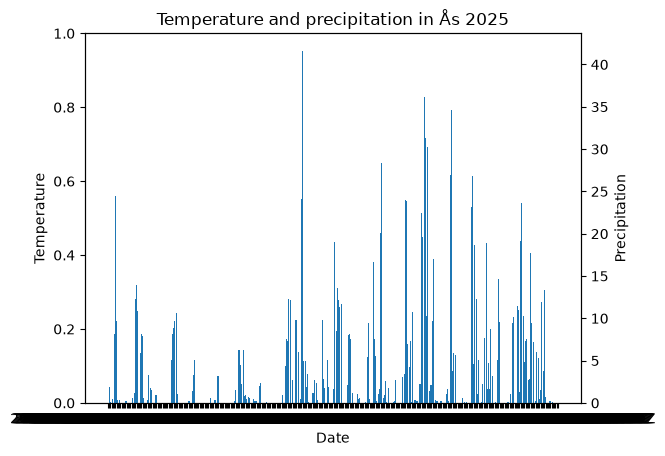

In [28]:
parameters = {'sources': 'SN17850',
              'elements': 'sum(precipitation_amount P1D)',
              'referencetime': '2025-01-01/2025-12-31',
            }

frost_r = requests.get(endpoint, parameters, auth=(client_id, ""))
assert frost_r.status_code == 200

json = frost_r.json()

data2 = json['data']

list2 = []
df2 = pd.DataFrame()
for i in range(len(data2)):
    row = pd.DataFrame(data2[i]['observations'])
    row['referenceTime'] = data2[i]['referenceTime']
    row['sourceId'] = data2[i]['sourceId']
    list2.append(row)

df2 = pd.concat(list2)
df2 = df2.reset_index()

fig, ax1 = plt.subplots()

ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature')
ax2 = ax1.twinx()
ax2.bar(df2['referenceTime'], df2['value'], label='Precipitation')
ax2.set_ylabel('Precipitation')

plt.title('Temperature and precipitation in Ås 2025')
plt.show()

Task 3: Historical temperature data

Task 4: Heatwaves

Task 5: Moving average temperature